
p=0.8
Feature strengths: [0.26 0.84 0.3  0.81 0.77]
Cosine similarity:
 [[ 1.    0.04  0.75 -0.91 -0.79]
 [ 0.04  1.   -0.63  0.37 -0.65]
 [ 0.75 -0.63  1.   -0.96 -0.18]
 [-0.91  0.37 -0.96  1.    0.46]
 [-0.79 -0.65 -0.18  0.46  1.  ]]
1 active: MSE=0.1029, relative=1.050
2 active: MSE=0.0770, relative=0.393


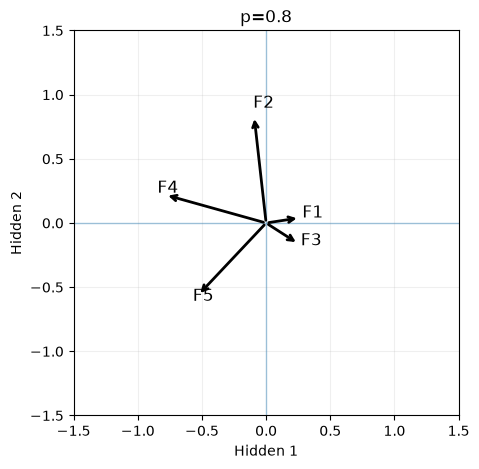


p=0.05
Feature strengths: [1.12 1.14 1.14 1.14 1.17]
Cosine similarity:
 [[ 1.    0.3   0.34 -0.81 -0.81]
 [ 0.3   1.   -0.8   0.32 -0.81]
 [ 0.34 -0.8   1.   -0.83  0.28]
 [-0.81  0.32 -0.83  1.    0.3 ]
 [-0.81 -0.81  0.28  0.3   1.  ]]
1 active: MSE=0.0012, relative=0.012
2 active: MSE=0.1214, relative=0.620


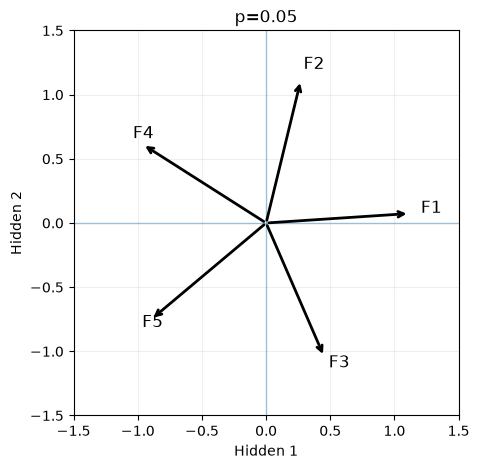

In [6]:

import itertools
import torch
import matplotlib.pyplot as plt

torch.set_num_threads(1)

def train(p):
    torch.manual_seed(1)
    W = torch.nn.Parameter(torch.randn(5, 2) * 0.3)
    b = torch.nn.Parameter(torch.zeros(5))
    optimizer = torch.optim.Adam([W, b], lr=0.03)

    for _ in range(1600):
        x = (torch.rand(256, 5) < p).float() * torch.rand(256, 5)
        prediction = torch.relu((x @ W) @ W.T + b)
        loss = ((prediction - x) ** 2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    return W.detach(), b.detach()


for p in [0.8, 0.05]:
    W, b = train(p)

    # 1. Measure the length of each feature direction
    norms = W.norm(dim=1)

    # 2. Measure pairwise cosine similarity
    cosine = (W @ W.T) / (norms[:, None] * norms[None, :])

    print(f"\np={p}")
    print("Feature strengths:", norms.numpy().round(2))
    print("Cosine similarity:\n", cosine.numpy().round(2))

    # 3. Measure reconstruction error
    for count in [1, 2]:
        combos = list(itertools.combinations(range(5), count))
        x = torch.zeros(len(combos), 5)

        for row, indices in enumerate(combos):
            x[row, list(indices)] = 0.7

        prediction = torch.relu((x @ W) @ W.T + b)

        mse = ((prediction - x) ** 2).mean().item()
        relative = ((prediction - x) ** 2).sum() / (x ** 2).sum()

        print(f"{count} active: MSE={mse:.4f}, relative={relative.item():.3f}")

    # 4. Visualize all five feature directions
    fig, ax = plt.subplots(figsize=(5, 5))

    for i, (vx, vy) in enumerate(W.tolist()):
        ax.annotate(
            "", xy=(vx, vy), xytext=(0, 0),
            arrowprops=dict(arrowstyle="->", lw=2)
        )
        ax.text(vx * 1.08, vy * 1.08, f"F{i+1}", fontsize=12)

    ax.axhline(0, lw=1, alpha=0.4)
    ax.axvline(0, lw=1, alpha=0.4)
    ax.set(
        xlim=(-1.5, 1.5), ylim=(-1.5, 1.5),
        xlabel="Hidden 1", ylabel="Hidden 2",
        title=f"p={p}"
    )
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    plt.show()


autoencoder -> project down dimension

sparse autoencoder(sae) -> project up dimension